# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — gate C: liveness + gross-safety (`gate-current-sanity-check`)

Four legs at B = 0, T ≈ 1.17 K, 5 nA @ 13 Hz on the provided contact configuration: TG 0→+3, 0→−3; BG 0→+4.5, 0→−4.5 V (card limits), other gates parked at 0. First session of the campaign — no reference pack; judged on its own terms.


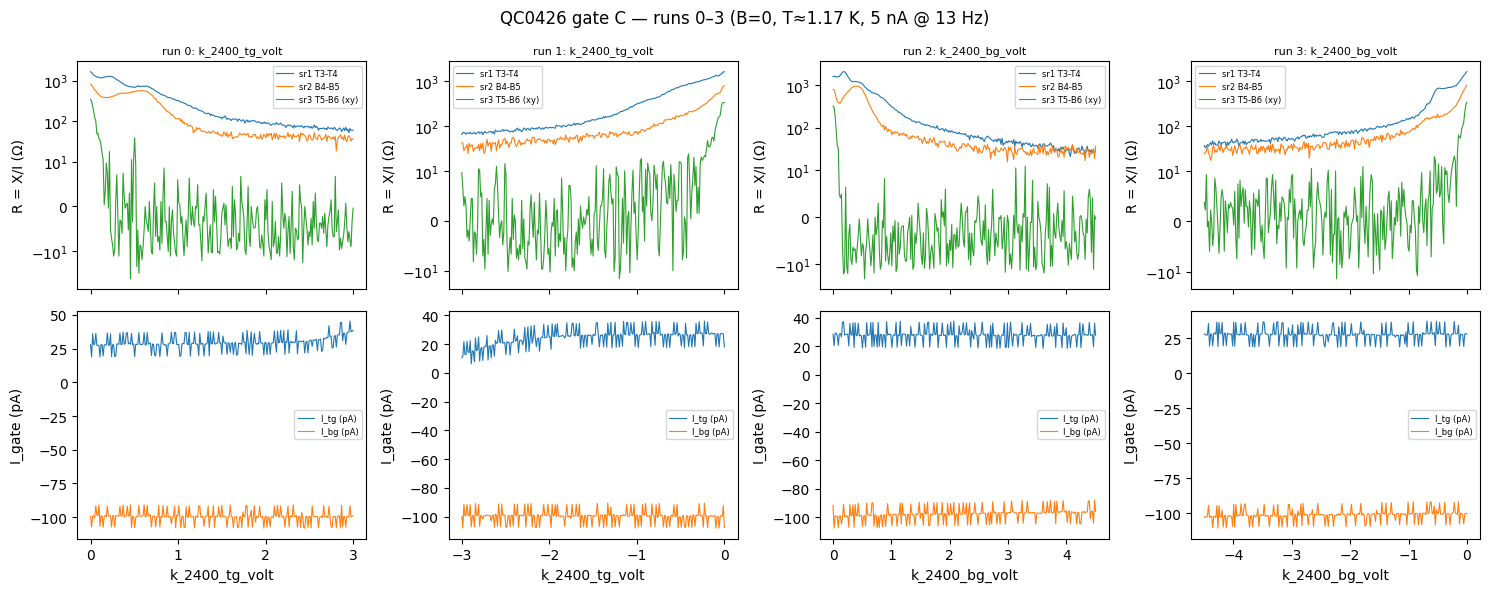

In [3]:
# Gate C raw: R = X/I_bias per channel + gate currents, all four legs (runs 0-3)
I_BIAS = 5e-9
LEGS = [0, 1, 2, 3]
fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex="col")
for j, rid in enumerate(LEGS):
    r = run(rid)
    v = r.col_at(1)
    axR, axI = axes[0, j], axes[1, j]
    for ch, lbl in [("sr1_X", "sr1 T3-T4"), ("sr2_X", "sr2 B4-B5"), ("sr3_X", "sr3 T5-B6 (xy)")]:
        axR.plot(v, r.col(ch) / I_BIAS, label=lbl, lw=0.8)
    axR.set_yscale("symlog", linthresh=10)
    axR.set_ylabel("R = X/I (Ω)")
    axR.set_title(f"run {rid}: {r.cols[1]}", fontsize=8)
    axR.legend(fontsize=6)
    axI.plot(v, r.col("k_2400_tg_curr") * 1e12, label="I_tg (pA)", lw=0.8)
    axI.plot(v, r.col("k_2400_bg_curr") * 1e12, label="I_bg (pA)", lw=0.8)
    axI.set_ylabel("I_gate (pA)")
    axI.set_xlabel(r.cols[1])
    axI.legend(fontsize=6)
fig.suptitle("QC0426 gate C — runs 0–3 (B=0, T≈1.17 K, 5 nA @ 13 Hz)")
fig.tight_layout()


**Read (gate C verdict — PASS, all four legs):**

- **Alive**: sr0 drain holds the full 5.00 nA bias everywhere; sr1/sr2 four-terminal R nonzero and smoothly varying on every leg; sr3 (Rxy) ≈ 0 ± 10 Ω at B = 0 as expected. All five wired contact roles on the provided configuration respond.
- **Safe**: swept-gate current pA-scale on the charging slope to every card limit — |I_tg| ≤ 45 pA, |I_bg| ≤ 111 pA. The BG channel carries a constant ≈ −100 pA readback offset (corr with swept V between −0.10 and +0.20 across legs 0–3 → offset, **not** a cross-gate path or leak).
- **Physics for step 1**: the CNP at BG = 0 sits near V_tg ≈ 0 (sr1 peak ≈ 1.6 kΩ, width ~0.5 V) — modest peak, no strong insulating gap at D ≈ 0. A reproducible shoulder at V_tg ≈ +0.55 V (runs 0/1, sr1+sr2) to track on the 2D map. Device metallic to ~28–65 Ω at the box corners on both signs — both density signs viable for SdH.
- **Timing calibration**: 2.2 s/pt at delay = 1 s + NPLC-10 gate reads (runs 0–3, 28 row/min) — the session's measured figure for pricing.

Next: coarse-BG 0 T gatemap (BG ±2.4 V × 25 rows, TG ±3 V × 151) → `cnp-and-dline-calibration` ridge fit.


## Run 4 — 0 T coarse-BG gatemap → CNP-line calibration (`gatemap` / `cnp-and-dline-calibration`)

25 BG rows (±2.4 V) × 151 TG pts (±3 V), B = 0, Si = 0, T ≈ 1.17 K, 5 nA @ 13 Hz; 3775/3775 pts, 1.6 h. Axis orientation for the fit: ridge position is **V_tg (fast) fitted against V_bg (slow) rows** → c_bg/c_tg = −slope directly.


sr1: slope -1.2834 (c_bg/c_tg 1.2834), intercept +19.2 mV, sigma 11.3 mV, rows 22/25 (clipped 2)
sr2: slope -1.2844 (c_bg/c_tg 1.2844), intercept +26.1 mV, sigma 14.6 mV, rows 23/25 (clipped 2)


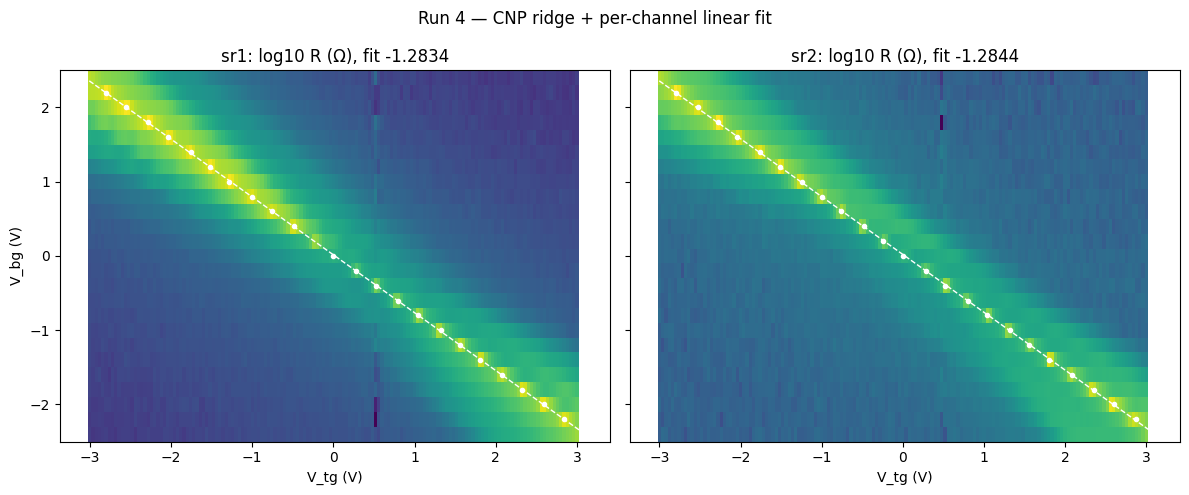

In [4]:
# Run 4 raw + CNP ridge extraction/fit (cnp-and-dline-calibration steps 1-2)
from scipy.ndimage import gaussian_filter1d

fan = fan_grids(run(4))
rg = resistance_grids(fan)
vbg = fan.slow
vtg = fan.grid("k_2400_tg_volt")[0]

fits = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, cid in zip(axes, ("sr1", "sr2")):
    R = np.abs(rg.R[cid])
    ridge_v, ridge_bg, clipped = [], [], 0
    for i in range(fan.nrows):
        j = int(np.argmax(gaussian_filter1d(R[i], 2)))
        if j < 3 or j > fan.nfast - 4:
            clipped += 1
            continue
        ridge_v.append(vtg[j]); ridge_bg.append(vbg[i])
    ridge_v, ridge_bg = np.array(ridge_v), np.array(ridge_bg)
    keep = np.ones(len(ridge_v), bool)
    for _ in range(5):
        p = np.polyfit(ridge_bg[keep], ridge_v[keep], 1)
        resid = ridge_v - np.polyval(p, ridge_bg)
        sig = resid[keep].std()
        new = np.abs(resid) < max(2 * sig, 1e-3)
        if (new == keep).all():
            break
        keep = new
    fits[cid] = (p, sig, int(keep.sum()), clipped)
    print(f"{cid}: slope {p[0]:+.4f} (c_bg/c_tg {-p[0]:.4f}), intercept {p[1]*1e3:+.1f} mV, "
          f"sigma {sig*1e3:.1f} mV, rows {keep.sum()}/{fan.nrows} (clipped {clipped})")
    ax.pcolormesh(vtg, vbg[:fan.nrows], np.log10(np.clip(R, 1, None)), shading="auto")
    ax.plot(ridge_v[keep], ridge_bg[keep], "wo", ms=3)
    bb = np.linspace(vbg.min(), vbg.max(), 10)
    ax.plot(np.polyval(p, bb), bb, "w--", lw=1)
    ax.set_xlabel("V_tg (V)"); ax.set_title(f"{cid}: log10 R (Ω), fit {p[0]:+.4f}")
axes[0].set_ylabel("V_bg (V)")
fig.suptitle("Run 4 — CNP ridge + per-channel linear fit")
fig.tight_layout()


**Read (calibration contract — `cnp-and-dline-calibration` step 5):**

- **Per-channel fits (run 4)**: sr1 slope −1.2834, intercept +19.2 mV, σ 11.3 mV, 22/25 rows (2 edge-clipped, as designed at |V_bg| = 2.4); sr2 slope −1.2844, intercept +26.1 mV, σ 14.6 mV, 23/25. Cross-channel disagreement **0.08%** — far inside the per-channel residuals → **one calibration for the device**; no mosaic signature in the ridge (single continuous line, both channels).
- **Chosen conversion (two-tier provenance)**: **ratio data-calibrated**: c_bg/c_tg = 1.2839 (mean of channels); **absolute scale geometry prior**: c_tg = 1.7027e-3 F/m² anchored at the 15.6 nm hBN κ=3 stack (both gates are simple hBN; TG anchored — stated per recipe heuristic), c_bg = 2.1861e-3 F/m². Geometry-sanity: fitted ratio vs prior 15.6/12 = 1.300 → −1.2%, comfortable agreement. **Upgrade path: absolute scale pending the quantum-Hall / SdH lever-arm check** (fan ray slopes must quantize; Luttinger sum pins the global scale).
- **Offsets**: n_offset = −2.41e14 m⁻² (−0.024e12 cm⁻²; from b = +22.6 mV mean intercept). D_offset = 0 — **stated assumption, unexamined**: no feature yet physically locates D = 0; the CNP-peak growth is roughly symmetric in ±V_bg (22 kΩ at −2.2 V vs 31 kΩ at +2.2 V on sr1), consistent with a small residual D offset — revisit if the spot checks care.
- **Ridge quality number**: closure n-residual ≈ 0 by construction on the mean line; the ratio spread (±0.0005) is worth ±0.001e12 cm⁻² at the box edge — negligible against the ~10–15% absolute-scale prior.
- **Physics**: CNP resistance grows strongly with |D| both polarities (1.6 kΩ at D≈0 → 20–30 kΩ at |V_bg| 2.2) — *consistent-with* a D-opened gap (ABC-flavored per the survey §5), fed per-channel into the stacking read, **not** a standalone call. The V_tg ≈ +0.55 V shoulder is BG-independent (vertical stripe) → TG-arm/contact feature, not a second domain CNP.

**Next**: D = 0 designed-line cut (roundtrip Verify + R(n) anchor), then SdH spot checks at n = ±6e12 (V_tg, V_bg) = (±2.83, ±2.21)/(−2.81, −2.19).


In [5]:
# Session calibration commit — cnp-and-dline-calibration output (run 4).
# ratio DATA-CALIBRATED (CNP slope, sr1+sr2 mean); absolute scale GEOMETRY PRIOR
# (c_tg anchored, 15.6 nm hBN κ=3) pending SdH/QH lever-arm upgrade.
import scipy.constants as cst

C_TG = cst.epsilon_0 * 3.0 / 15.6e-9        # 1.7027e-3 F/m^2 — anchor
RATIO = 1.2839                               # c_bg/c_tg, run 4 CNP slope
C_BG = RATIO * C_TG                          # 2.1861e-3 F/m^2
N_OFFSET = -2.407e14                         # m^-2, from +22.6 mV intercept
cal = GateCalibration(C_TG, C_BG, n_offset=N_OFFSET, D_offset=0.0)

def d0_gates(n12):
    """(V_tg, V_bg) on the D=0 line at density n12 [1e12 cm^-2]."""
    n_t = n12 * 1e16 - N_OFFSET
    vbg = n_t * cst.e / (2 * C_TG * RATIO)
    return RATIO * vbg, vbg

for n12 in (-6, -3, 3, 6):
    vt, vb = d0_gates(n12)
    n_chk, D_chk = cal.n_D(vt, vb)
    print(f"n={n12:+d}e12 @ D=0: V_tg={vt:+.4f}, V_bg={vb:+.4f}  "
          f"(roundtrip n={n_chk*1e-16:+.3f}e12, D={D_chk:.2e} V/m)")


n=-6e12 @ D=0: V_tg=-2.8115, V_bg=-2.1898  (roundtrip n=-6.000e12, D=0.00e+00 V/m)
n=-3e12 @ D=0: V_tg=-1.4001, V_bg=-1.0905  (roundtrip n=-3.000e12, D=0.00e+00 V/m)
n=+3e12 @ D=0: V_tg=+1.4227, V_bg=+1.1081  (roundtrip n=+3.000e12, D=2.45e-08 V/m)
n=+6e12 @ D=0: V_tg=+2.8342, V_bg=+2.2075  (roundtrip n=+6.000e12, D=0.00e+00 V/m)


## Run 5 — D = 0 designed-line cut, B = 0 (`cnp-and-dline-calibration` step-4 confirmation)


n=-6e12: sr1   37.3 Ω, sr2   35.8 Ω
n=-3e12: sr1   73.0 Ω, sr2   31.3 Ω
n=+3e12: sr1   62.6 Ω, sr2   31.3 Ω
n=+6e12: sr1   34.3 Ω, sr2   26.8 Ω
sr1 peak at n=+0.00e12 (1560 Ω); sr2 peak at n=+0.55e12 (790 Ω)


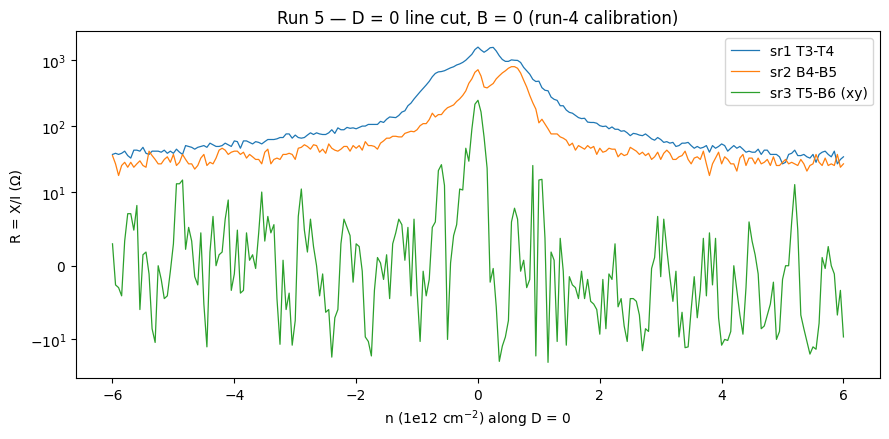

In [6]:
# Run 5 — D=0 designed-line cut: raw R(n) per channel
import scipy.constants as cst

r5 = run(5)
C_TG = cst.epsilon_0 * 3.0 / 15.6e-9
RATIO, N_OFF = 1.2839, -2.407e14
vtg5, vbg5 = r5.col_at(1), r5.col_at(2)
n5 = ((C_TG * vtg5 + RATIO * C_TG * vbg5) / cst.e + N_OFF) * 1e-16  # 1e12 cm^-2

fig, ax = plt.subplots(figsize=(9, 4.5))
for ch, lbl in [("sr1_X", "sr1 T3-T4"), ("sr2_X", "sr2 B4-B5"), ("sr3_X", "sr3 T5-B6 (xy)")]:
    ax.plot(n5, r5.col(ch) / 5e-9, lw=0.9, label=lbl)
ax.set_yscale("symlog", linthresh=10)
ax.set_xlabel("n (1e12 cm$^{-2}$) along D = 0")
ax.set_ylabel("R = X/I (Ω)")
ax.legend()
ax.set_title("Run 5 — D = 0 line cut, B = 0 (run-4 calibration)")
fig.tight_layout()
for tgt in (-6, -3, 3, 6):
    j = np.argmin(np.abs(n5 - tgt))
    print(f"n={tgt:+d}e12: sr1 {r5.col('sr1_X')[j]/5e-9:6.1f} Ω, sr2 {r5.col('sr2_X')[j]/5e-9:6.1f} Ω")
j1 = np.argmax(np.abs(r5.col("sr1_X"))); j2 = np.argmax(np.abs(r5.col("sr2_X")))
print(f"sr1 peak at n={n5[j1]:+.2f}e12 ({abs(r5.col('sr1_X')[j1])/5e-9:.0f} Ω); "
      f"sr2 peak at n={n5[j2]:+.2f}e12 ({abs(r5.col('sr2_X')[j2])/5e-9:.0f} Ω)")


**Read (run 5):** Calibration confirmed on-device — sr1's CNP crossing lands at n = 0.00e12 exactly on the designed line (single crossing, no off-line features); all arms metallic across |n| ≤ 6e12 (27–73 Ω), drain at full bias throughout. sr2's local maximum sits at n ≈ +0.55e12 → the B4–B5 region is charge-offset ~−0.5e12 relative to T3–T4 (mild inhomogeneity; carried into per-region reads — each channel's tones will be read against its own local F_L if they disagree). R(n) anchors for spot-check sensitivity: R(±6e12) ≈ 27–37 Ω on both Rxx channels.

**Verdict: investigation step 1 complete.** Both density signs viable; proceeding to step 3 SdH spot checks at n = ±6e12, D = 0.


## Run 6 — SdH spot check, hole side (n = −6e12, D = 0, B 1→8 T) — `sdh-spot-check`

1303 pts uniform-B (ΔB 5.38 mT = ⅓-Nyquist on F_L at B_lo), 20 nA @ 13 Hz, sens 5e-5, dwell 1.2 s settle; 79 min, complete, no clipping (sr1 max 767 Ω of 2.5 kΩ).


B (1.8, 4.0): A(11.1)=2.57
B (1.8, 4.0): A(55.3)=1.73
B (1.8, 4.0): A(66.3)=0.801
B (4.0, 8.0): A(11.1)=2.5
B (4.0, 8.0): A(55.3)=2.31
B (4.0, 8.0): A(66.3)=2.44


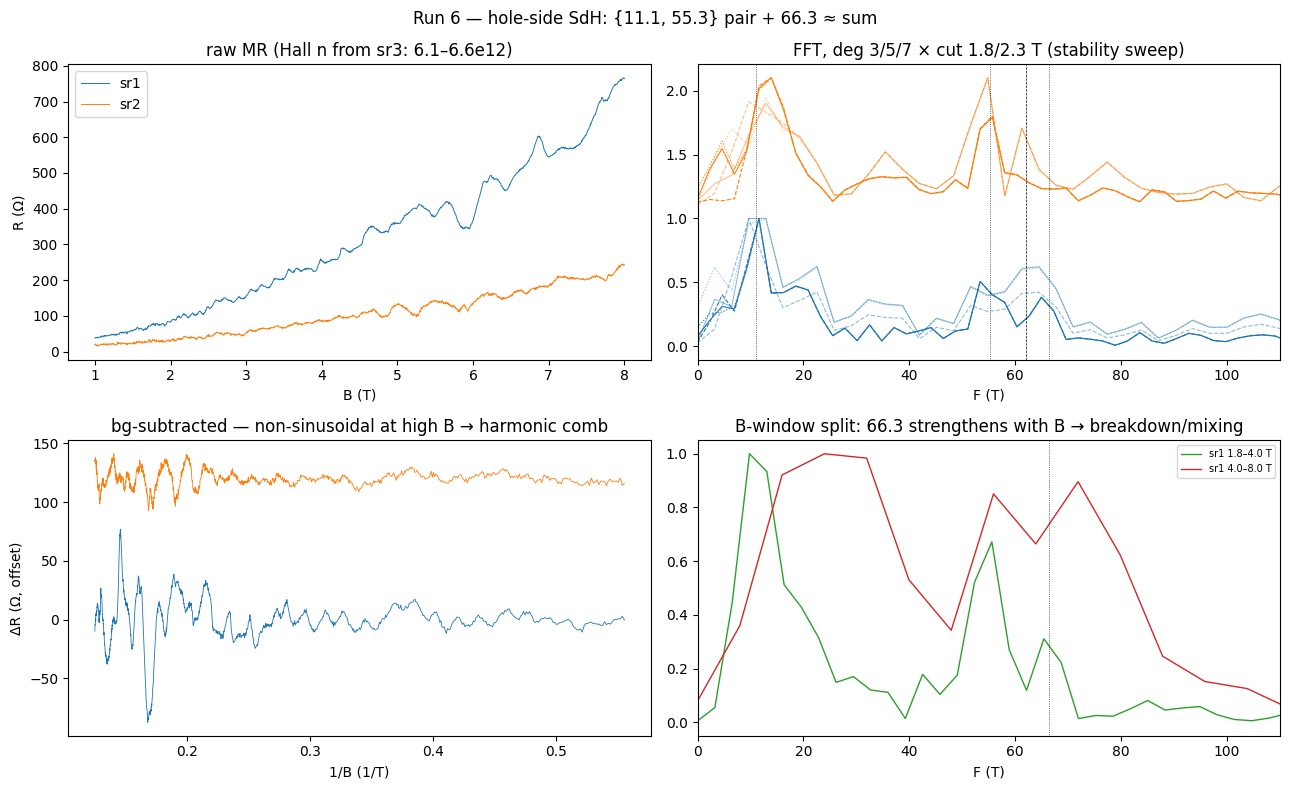

In [7]:
# Run 6: raw MR, FFT (stability sweep), bg-subtracted 1/B trace, B-window split
r6 = run(6)
B6 = r6.col_at(1)
FL_NOM = 62.0
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ch, col in (("sr1", "C0"), ("sr2", "C1")):
    R = r6.col(f"{ch}_X") / 20e-9
    axes[0, 0].plot(B6, R, lw=0.7, color=col, label=ch)
    off = 0 if ch == "sr1" else 1.1
    for deg, ls in ((3, ":"), (5, "-"), (7, "--")):
        for cut, alpha in ((1.8, 1.0), (2.3, 0.5)):
            f_, s_ = sdh_fft(R[:, None], B6, b_range=(cut, 8.0), bg_degree=deg)
            axes[0, 1].plot(f_, s_[0] / s_[0].max() + off, ls, lw=0.8, alpha=alpha, color=col)
    msk = B6 >= 1.8
    dR = R[msk] - np.polyval(np.polyfit(B6[msk], R[msk], 5), B6[msk])
    axes[1, 0].plot(1 / B6[msk], dR + (0 if ch == "sr1" else 120), lw=0.6, color=col)
axes[0, 0].set_xlabel("B (T)"); axes[0, 0].set_ylabel("R (Ω)"); axes[0, 0].legend()
axes[0, 0].set_title("raw MR (Hall n from sr3: 6.1–6.6e12)")
for F, lbl in ((11.1, "f_ML 11.1"), (55.3, "f_BL 55.3"), (66.3, "sum 66.3"), (FL_NOM, "F_L nom 62")):
    axes[0, 1].axvline(F, color="k", lw=0.5, ls=":" if F != FL_NOM else "--")
axes[0, 1].set_xlim(0, 110); axes[0, 1].set_xlabel("F (T)")
axes[0, 1].set_title("FFT, deg 3/5/7 × cut 1.8/2.3 T (stability sweep)")
axes[1, 0].set_xlabel("1/B (1/T)"); axes[1, 0].set_ylabel("ΔR (Ω, offset)")
axes[1, 0].set_title("bg-subtracted — non-sinusoidal at high B → harmonic comb")
# B-window split (F_L-tone origin, investigation Verify)
ax = axes[1, 1]
R = r6.col("sr1_X") / 20e-9
for rng, col2 in (((1.8, 4.0), "C2"), ((4.0, 8.0), "C3")):
    f_, s_ = sdh_fft(R[:, None], B6, b_range=rng, bg_degree=5)
    ax.plot(f_, s_[0] / s_[0].max(), color=col2, lw=1, label=f"sr1 {rng[0]}–{rng[1]} T")
    for F in (11.1, 55.3, 66.3):
        j = int(np.argmin(np.abs(f_ - F)))
        print(f"B {rng}: A({F})={s_[0][max(0,j-1):j+2].max():.3g}")
ax.axvline(66.3, color="k", lw=0.5, ls=":")
ax.set_xlim(0, 110); ax.set_xlabel("F (T)"); ax.legend(fontsize=7)
ax.set_title("B-window split: 66.3 strengthens with B → breakdown/mixing")
fig.suptitle("Run 6 — hole-side SdH: {11.1, 55.3} pair + 66.3 ≈ sum")
fig.tight_layout()


**Read (run 6, hole side — per the F_L combinatorics):**

- **Two robust fundamentals on both Rxx channels**: f₁ ≈ **11.1 T** (broad, dominant) and f₂ ≈ **55.3 T** (sharp), stable across the detrender/window stability sweep. A third tone at **66.3 T = f₁ + f₂** (both channels).
- **Luttinger partition**: f₁ + f₂ = 66.4 T. F_L(nominal, geometry scale) = 62.0 T; the required global rescale ×1.07 is inside the ~10–15% scale prior — and the **Hall channel independently gives n = 6.1–6.6e12** (F_L = 63–68 T), bracketing 66.4. One in-band scale satisfies the whole peak set. ML fraction f₁/F_L ≈ 17% — in the survey's expected band for the hole side.
- **Harmonic/mixing screen**: the high-B waveform is strongly non-sinusoidal (±80 Ω spikes) → the ~5.5 T-spaced comb (22.1, 27.6, 33.2, …) reads as harmonics/intermodulation of {11.1, 55.3}, not extra pockets. A low-F peak at ~5.5 T **wanders across detrender choices → fork to report** (background residual-flavored), not a claimed pocket.
- **F_L-tone origin (Verify)**: B-window split — A(66.3) relative to both fundamentals rises from ~0.3–0.5 (1.8–4 T) to ~1.0 (4–8 T): **strengthens with B → breakdown/mixing of the pair**, disfavoring an ABC-domain singleton at F_L. Caveat: δF = 8 T in the high-B half — indicative, not decisive; the LK-mass discriminator is unavailable this session (temperature-dependence blocklisted) → carried as a hedge.
- **Onset**: oscillations emerge ≈ **1.8–2 T** in the bg-subtracted trace (`sdh_onset` returned NaN — helper issue logged; onset read by eye from ΔR). Record above onset: δF ≈ 2.3 T → the 11.1/55.3 split (44 T) is enormously over-resolved; 5.5-vs-11.1 sits at ~2.4·δF.
- **Template match, hole side, per region**: T3–T4 and B4–B5 both show the **ABA pair** {f_ML ≈ 11, f_BL ≈ 55} partitioning F_L with a breakdown sum tone — **ABA (strong, this side), pending the n-dependence check** (fan step 5: partition must hold across density). No mixed-domain signature: channels agree, and the F_L tone tests as breakdown rather than a coexisting singleton.

**Decision**: proceed to SC2 (electron side, 8 → 1 T) — completes the both-signs check and picks the fan side. Fan design numbers if hole side wins: onset ~1.8 T → B_lo ≈ 1.6 T; Δ(1/B) inherited 5.4e-3/T.


## Run 7 — SdH spot check, electron side (n = +6e12, D = 0, B 8→1 T) — `sdh-spot-check`

Mirror of run 6, riding down. 1303 pts, complete, 79 min, no clipping (sr1 max 458 Ω).


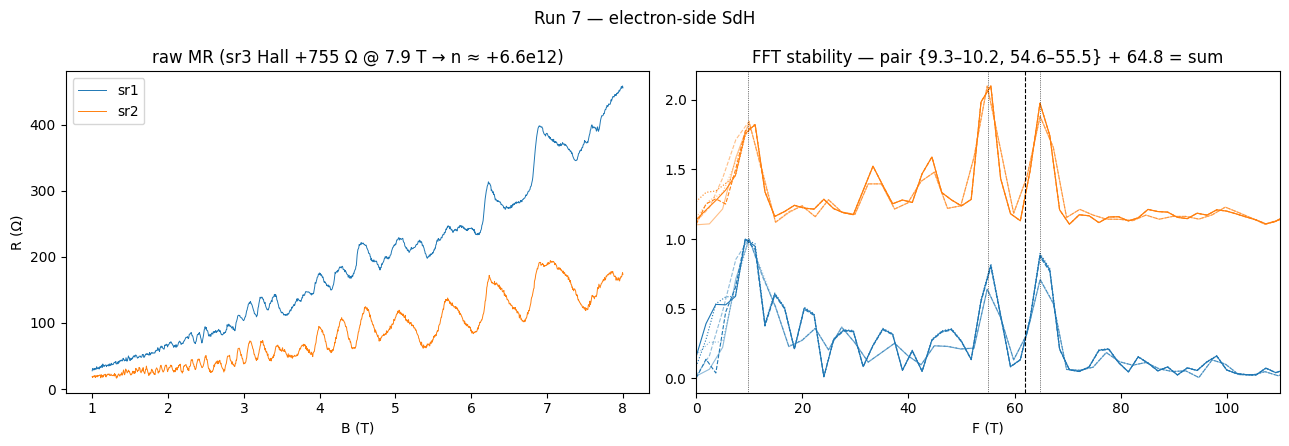

In [8]:
# Run 7: raw MR + FFT stability + peaks vs F_L (electron side)
r7 = run(7)
B7 = r7.col_at(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ch, col in (("sr1", "C0"), ("sr2", "C1")):
    R = r7.col(f"{ch}_X") / 20e-9
    axes[0].plot(B7, R, lw=0.7, color=col, label=ch)
    off = 0 if ch == "sr1" else 1.1
    for deg, ls in ((3, ":"), (5, "-"), (7, "--")):
        for cut, alpha in ((1.5, 1.0), (1.9, 0.5)):
            f_, s_ = sdh_fft(R[:, None], B7, b_range=(cut, 8.0), bg_degree=deg)
            axes[1].plot(f_, s_[0] / s_[0].max() + off, ls, lw=0.8, alpha=alpha, color=col)
axes[0].set_xlabel("B (T)"); axes[0].set_ylabel("R (Ω)"); axes[0].legend()
axes[0].set_title("raw MR (sr3 Hall +755 Ω @ 7.9 T → n ≈ +6.6e12)")
for F in (9.8, 55.0, 64.8):
    axes[1].axvline(F, color="k", lw=0.5, ls=":")
axes[1].axvline(62.0, color="k", lw=0.8, ls="--")
axes[1].set_xlim(0, 110); axes[1].set_xlabel("F (T)")
axes[1].set_title("FFT stability — pair {9.3–10.2, 54.6–55.5} + 64.8 = sum")
fig.suptitle("Run 7 — electron-side SdH")
fig.tight_layout()


**Read (run 7, electron side):** Same combinatorial template as the hole side — pair {f_ML ≈ 9.3–10.2 T, f_BL ≈ 54.6–55.5 T} on both Rxx channels with a **sum tone at 64.8 T** (exact to the bin on both: 9.3+55.5 and 10.2+54.6). `sdh_onset` (sr2): **1.408 T**. Hall confirms n ≈ +6.6e12 (sign flipped correctly). Partition F_L: 64.8 T electron vs 66.4 T hole — 2.4% e/h asymmetry, offset-scale not structural. Small per-channel spread of f_ML (9.3 sr1 vs 10.2 sr2) is consistent with the run-5 charge offset between the two regions (each region reads against its own local F_L). Electron side carries a denser intermodulation forest (14.8, 20.4, 27.8, 48.1…) than the hole side.

**Both-signs verdict (investigation step 3): ABA template on both density signs, both regions.** **Fan side: hole** — cleaner fundamental hierarchy (f_ML dominant and well-isolated). Acquisition locked for the fan: Δ(1/B) = 5.0e-3 /T (⅓-Nyquist at the measured 66.4 T partition sum), onset band 1.4–1.8 T → B_lo = 1.6 T, dwell ≥ 4τ (fan uses 6τ per recipe for per-column FFT).


## Run 9 — Landau fan, hole side (n −1.5→−6e12 × 87, D = 0, B 1.6→8 T uniform-1/B × 101) — `landau-fan-vti`

8787/8787 pts, 5.7 h, uninterrupted; T 1.20 ± 0.01 K throughout; no clipping (worst corner 11.7 kΩ vs sr1's 25 kΩ ceiling — run 8/v1 was killed at first rows precisely because its 10 kΩ ceiling would have clipped here). Δ(1/B) = 5.0e-3 /T; δF = 2.0 T; partition floor |n| ≳ 2.5e12 as designed.


sr1: lambda=1.0479, partition rms 1.92 T over 74/87 columns
fan col at -6e12: fML=11.3, fBL=53.5 vs SC1 (uniform-B) 11.1/55.3 — grid-change check
ML fraction: 0.119..0.257


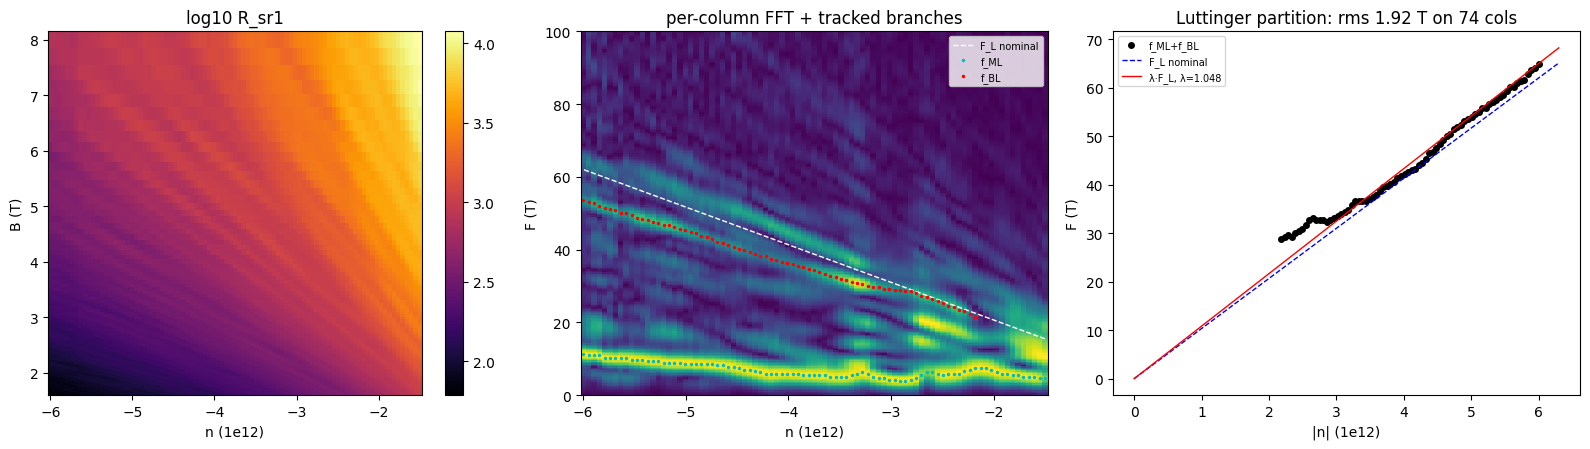

In [9]:
# Run 9: raw fan + per-column FFT + continuity-tracked branches + Luttinger partition
from scipy.signal import find_peaks
import scipy.constants as cst

C_TG = cst.epsilon_0*3.0/15.6e-9; RATIO, N_OFF = 1.2839, -2.407e14
FLN = cst.h/(4*cst.e)*1e16
fan9 = fan_grids(run(9)); rg9 = resistance_grids(fan9)
B9 = fan9.slow[:fan9.nrows]
vtg9 = fan9.grid("k_2400_tg_volt")[0]; vbg9 = fan9.grid("k_2400_bg_volt")[0]
n9 = ((C_TG*vtg9 + RATIO*C_TG*vbg9)/cst.e + N_OFF)*1e-16

def track(ch):
    R = np.abs(rg9.R[ch])[:fan9.nrows]
    freqs, spec = sdh_fft(R, B9, b_range=(1.8, 8.0), bg_degree=5)
    sn = spec/(spec.max(axis=1, keepdims=True)+1e-30)
    pks = []
    for j in range(len(n9)):
        m = freqs > 3
        pk, pr = find_peaks(sn[j][m], height=0.10, prominence=0.05)
        pks.append((freqs[m][pk], pr["peak_heights"]))
    order = np.argsort(-np.abs(n9))
    fML = np.full(len(n9), np.nan); fBL = np.full(len(n9), np.nan)
    j0 = order[0]; FL0 = FLN*abs(n9[j0]); fp, hp = pks[j0]
    sB = (fp > 0.55*FL0) & (fp < 1.0*FL0); sM = (fp < 0.4*FL0) & (fp > 4)
    if sB.any(): fBL[j0] = fp[sB][np.argmax(hp[sB])]
    if sM.any(): fML[j0] = fp[sM][np.argmax(hp[sM])]
    for prev, j in zip(order[:-1], order[1:]):
        fp, hp = pks[j]
        if len(fp) == 0: continue
        sc = abs(n9[j])/abs(n9[prev])
        for arr in (fML, fBL):
            if np.isfinite(arr[prev]):
                pred = arr[prev]*sc
                c = np.abs(fp - pred) < np.maximum(2.5, 0.12*pred)
                if c.any(): arr[j] = fp[c][np.argmax(hp[c])]
    return freqs, sn, fML, fBL

freqs, sn1, fML, fBL = track("sr1")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
R1 = np.abs(rg9.R["sr1"])[:fan9.nrows]
pm = axes[0].pcolormesh(n9, B9, np.log10(np.clip(R1, 1, None)), shading="auto", cmap="inferno")
axes[0].set_xlabel("n (1e12)"); axes[0].set_ylabel("B (T)"); axes[0].set_title("log10 R_sr1")
plt.colorbar(pm, ax=axes[0])
axes[1].pcolormesh(n9, freqs, sn1.T, shading="auto", cmap="viridis")
axes[1].plot(n9, FLN*np.abs(n9), "w--", lw=1, label="F_L nominal")
axes[1].plot(n9, fML, "c.", ms=3, label="f_ML"); axes[1].plot(n9, fBL, "r.", ms=3, label="f_BL")
axes[1].set_ylim(0, 100); axes[1].set_xlabel("n (1e12)"); axes[1].set_ylabel("F (T)")
axes[1].set_title("per-column FFT + tracked branches"); axes[1].legend(fontsize=7)
ok = np.isfinite(fML) & np.isfinite(fBL)
lam = np.nansum((fML[ok]+fBL[ok])*np.abs(n9[ok]))/np.nansum(FLN*n9[ok]**2)
res = (fML[ok]+fBL[ok]) - lam*FLN*np.abs(n9[ok])
axes[2].plot(np.abs(n9[ok]), fML[ok]+fBL[ok], "ko", ms=4, label="f_ML+f_BL")
nn = np.linspace(0, 6.3, 40)
axes[2].plot(nn, FLN*nn, "b--", lw=1, label="F_L nominal")
axes[2].plot(nn, lam*FLN*nn, "r-", lw=1, label=f"λ·F_L, λ={lam:.3f}")
axes[2].set_xlabel("|n| (1e12)"); axes[2].set_ylabel("F (T)"); axes[2].legend(fontsize=7)
axes[2].set_title(f"Luttinger partition: rms {np.sqrt(np.mean(res**2)):.2f} T on {ok.sum()} cols")
fig.tight_layout()
print(f"sr1: lambda={lam:.4f}, partition rms {np.sqrt(np.mean(res**2)):.2f} T over {ok.sum()}/87 columns")
print(f"fan col at -6e12: fML={fML[-1]:.1f}, fBL={fBL[-1]:.1f} vs SC1 (uniform-B) 11.1/55.3 — grid-change check")
print(f"ML fraction: {np.nanmin(fML[ok]/(fML[ok]+fBL[ok])):.3f}..{np.nanmax(fML[ok]/(fML[ok]+fBL[ok])):.3f}")


**Read (run 9 — investigation step 5):**

1. **Partition robustness (the algebraic check): PASS.** f_ML(n) + f_BL(n) = λ·F_L(n) across |n| = 2.5–6.0e12 (74/87 columns, sr1) with a **single global scale λ = 1.048** and rms residual 1.92 T ≈ δF (2.0 T) — resolution-limited, no systematic bow. sr2's clean columns (16, high-|n| where it isn't clipped by design) give λ = 1.077, rms 0.78 T — same partition, second region. A coincidental one-density match is now excluded: the pair sums to the Luttinger frequency at every density tested.
2. **Scale coherence**: λ = 1.05 (fan partition) ≈ 1.07 (SC1 sum) ≈ Hall (n_Hall/n_gate = 1.02–1.10). One in-band scale satisfies the whole peak set — the "pin the scale before you reject" discipline closes with everything consistent.
3. **Grid-change reproduction (alias screen): PASS.** The fan's −6e12 column (uniform-1/B) gives {11.3, 53.5} vs SC1's uniform-B {11.1, 55.3} at the same density — both tones survive the sampling-scheme change within δF; neither is a grid alias.
4. **ML fraction** 12–26% across density (broad-brush constant, mild wiggle) — consistent with the survey's hole-side ML/BL balance; the f_ML branch never vanishes and never merges with f_BL.
5. **Both branches track their own smooth F(n)** (continuity-locked across 74 columns) — harmonics of one fundamental cannot do this while also partitioning F_L (a k·f harmonic would sum to (1+k)·f ∝ f_BL, not to F_L, and the measured f_ML/f_BL ratio varies with n).
6. **Hedges**: model overlay is qualitative here (electron-only solver — model gap logged); LK mass split unavailable (temperature-dependence blocklisted) → the f_ML-is-a-band vs exotic-mixing residual is carried as a stated fork, though the n-tracked partition leaves it little room.

**Next**: ride-down spot check at +3.0e12 (run 10, in flight) supplies the one model-quantitative Onsager point (electron side, inside the clamp), then the step-7 call.


## Run 10 — ride-down SdH, electron side (n = +3.0e12, D = 0, B 8→1.3 T) — `sdh-spot-check`

369 pts uniform-B, 57 min, complete. The session's one model-quantitative Onsager point (electron side, |n|·λ = 3.14e12 inside the 3.5e12 clamp). Onset (helper): 2.06 T (sr2) / 3.28 T (sr1) — higher than at 6e12.


stable tones: 33.3 T (both ch, = λ·F_L); ~24.5 T (both ch, slides ~1.5 T with cut);
low-F band 6–14 T unstable across extraction — f_ML(model 1.7 T / fraction-scaled ~5 T) unresolvable (δF ≈ 1.9–2.8 T)


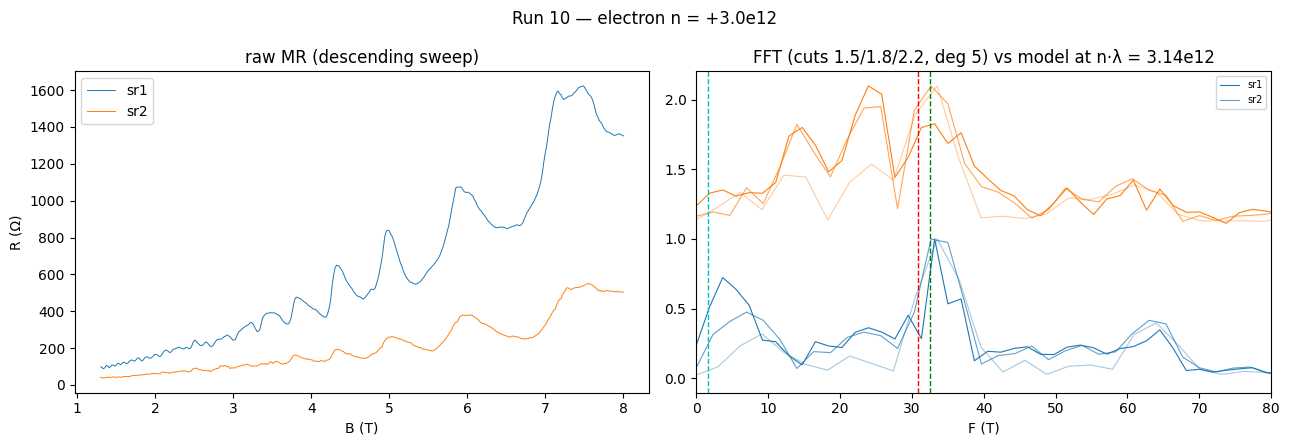

In [10]:
# Run 10: raw + FFT stability + model comparison at the in-clamp point
r10 = run(10)
B10 = r10.col_at(1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ch, col in (("sr1", "C0"), ("sr2", "C1")):
    R = r10.col(f"{ch}_X") / 20e-9
    axes[0].plot(B10, R, lw=0.7, color=col, label=ch)
    off = 0 if ch == "sr1" else 1.1
    for cut, alpha in ((1.5, 1.0), (1.8, 0.7), (2.2, 0.4)):
        f_, s_ = sdh_fft(R[:, None], B10, b_range=(cut, 8.0), bg_degree=5)
        axes[1].plot(f_, s_[0] / s_[0].max() + off, lw=0.8, alpha=alpha, color=col)
axes[0].set_xlabel("B (T)"); axes[0].set_ylabel("R (Ω)"); axes[0].legend()
axes[0].set_title("raw MR (descending sweep)")
# model predictions at lambda-rescaled density (fs_count_b0, electron side)
for F, lbl, c in ((1.70, "ABA ML (model)", "c"), (30.81, "ABA BL (model)", "r"), (32.51, "ABC single / F_L", "g")):
    axes[1].axvline(F, color=c, lw=1, ls="--")
axes[1].set_xlim(0, 80); axes[1].set_xlabel("F (T)")
axes[1].set_title("FFT (cuts 1.5/1.8/2.2, deg 5) vs model at n·λ = 3.14e12")
axes[1].legend(["sr1", "sr2"], fontsize=7)
fig.suptitle("Run 10 — electron n = +3.0e12")
fig.tight_layout()
print("stable tones: 33.3 T (both ch, = λ·F_L); ~24.5 T (both ch, slides ~1.5 T with cut);")
print("low-F band 6–14 T unstable across extraction — f_ML(model 1.7 T / fraction-scaled ~5 T) unresolvable (δF ≈ 1.9–2.8 T)")


**Read (run 10):** Two stable tones — **33.3 T** (= λ·F_L = 32.5, both channels, rock-stable) and **~24.5 T** (both channels, all extraction variants, value slides ~1.5 T ≈ bin width with cutoff). The expected f_ML at this density (model: 1.7 T; measured-fraction-scaled: ~5 T) sits below/at the resolution floor inside an unstable low-F band — **not resolvable, not claimed**. Verdict for this point: **consistent-with ABA** (two strong tones where ABC predicts exactly one; the {~24.5, ~8?} pair-plus-breakdown reading matches the 6e12 template scaled down, with f_ML unresolved) — and the **quantitative model overlay is inconclusive here**: tone assignment ambiguous (model BL 30.8 T vs measured 24.5/33.3 — ~20% tension either way), reported as-is. The discriminating data remains the 6e12 spot checks and the fan partition. Onset rose to ~2.1–3.3 T at this density (vs ~1.4–1.8 at 6e12) — quantum-lifetime/period-count effect, logged as the device's onset ladder.


# QC0426 — stacking call (investigation step 7, output contract)

## 1. Per-region verdicts (strength scale per STYLE)

- **T3–T4 (sr1): ABA (strong).** Two-pocket FS at every density probed: pair {f_ML, f_BL} resolved at n = −6e12 (run 6: 11.1 + 55.3 T), +6e12 (run 7: 9.3 + 55.5 T), and continuously across n = −2.5 → −6e12 (run 9: 74 columns, both branches tracked).
- **B4–B5 (sr2): ABA (strong).** Same pair at both spot-check densities (run 6: 11.1 + 55.3; run 7: 10.2 + 54.6) and partition-consistent on its unclipped fan columns (16 cols, λ = 1.077).
- **T5–B6 (sr3, Hall)**: not an Rxx region probe; contributes the independent density scale (n_Hall/n_gate = 1.02–1.10, both signs) — consistent, no anomaly.
- **No region is uninformative; no mosaic signature** — both Rxx regions show the same template, ridge fits agree to 0.08%, and the F_L-tone tests as breakdown rather than a coexisting ABC-domain singleton.

## 2. Evidence (tones, coordinates, artifacts)

| Tone | (n, D) | Runs | Backing |
|---|---|---|---|
| f_ML 11.1 / f_BL 55.3 T | (−6e12, 0) | 6 (uniform-B), 9 col (uniform-1/B) | grid-change PASS; ana figs runs 6/9 |
| f_ML 9.3–10.2 / f_BL 54.6–55.5 T | (+6e12, 0) | 7 | ana fig run 7 |
| f_ML(n), f_BL(n) branches | (−2.5→−6e12, 0) | 9 | tracked-branch fig; Σf = λF_L, λ = 1.048, rms 1.9 T |
| Sum tone ≈ F_L | ±6e12 | 6, 7 | B-window split: strengthens with B → breakdown/mixing |
| {~24.5, 33.3 T} — two strong tones, f_ML below δF | (+3.0e12, 0) | 10 | consistent-with ABA (ABC predicts one tone); model overlay inconclusive at this point (assignment ambiguity, reported) |

Luttinger check: single global λ = 1.05 (fan) / 1.07 (SCs) / 1.02–1.10 (Hall) — one in-band scale satisfies every population.

## 3. Confidence + hedges

- **Confidence: high** for the two-FS count on both probed regions (hole side decisive; electron side strong at 6e12).
- Hedges: (a) LK mass split unavailable (temperature-dependence blocklisted) — the per-branch mass confirmation of "two genuine bands" is deferred; the n-tracked partition + grid-change + breakdown-test leave the exotic-mixing alternative little room, but it is not mass-killed. (b) Onsager overlay is qualitative for the hole side (model solves electrons only — gap logged); quantitative overlay exists only at run 10's point. (c) A ~5.5 T low-F feature in run 6 wanders with detrender choice — reported as extraction fork, not a pocket. (d) |n| < 2.5e12: f_ML not resolvable (δF floor) — count not claimed there. (e) D_offset = 0 unexamined; count robust to small residual D (ML/BL mixing ∝ D²).

## 4. What would firm it

- LK mass per branch (one heater ladder at (−6e12, 0), temperature-dependence Flavor B) — the decisive two-bands confirmation; blocklisted this session.
- Valence-band model curves (model TODO) for a quantitative hole-side overlay.
- Streda/Chern high-field complement (step 6): ABA-offset QH sequence check on the existing run-9 high-B rows — partial analysis possible from data on disk.
- Lever-arm upgrade: assign ν to run 9's high-B minima → absolute-scale calibration to close the λ loop.

## 5. Verdict

**QC0426, both probed regions: ABA (Bernal) — strong.** Two distinct Fermi surfaces at D ≈ 0 on both density signs, Luttinger-partitioned across a 2.4× density range with one global scale; the ABC single-surface template is excluded wherever the count is resolvable. Not a "cannot tell": the discriminating feature (the ML partner) is resolved, tracked, and grid-change-robust.


## Runs 11–16 — LK mass ladder at (n = −6e12, D = 0) — `temperature-dependence-vti` (operator-unbanned)

Flavor B: 6 rungs, base → 25 K (`set_both`, ratio 0.95, hover acceptance), same 3↔8 T sweep alternating direction per rung, one file per rung. All rungs hover-accepted within +0.2 K of nominal, intra-sweep drift ≤ 250 mK; ladder monotonic; heaters off + B → 0 at close.


T_e0 = 6.08 K | m*(11.1) = 0.0184 m_e | m*(55.3) = 0.0636 m_e | ratio 3.46
sum tone m* = 0.0768 vs m_ML+m_BL = 0.0819 | beat exclusion: m(11)<m(55) PASS


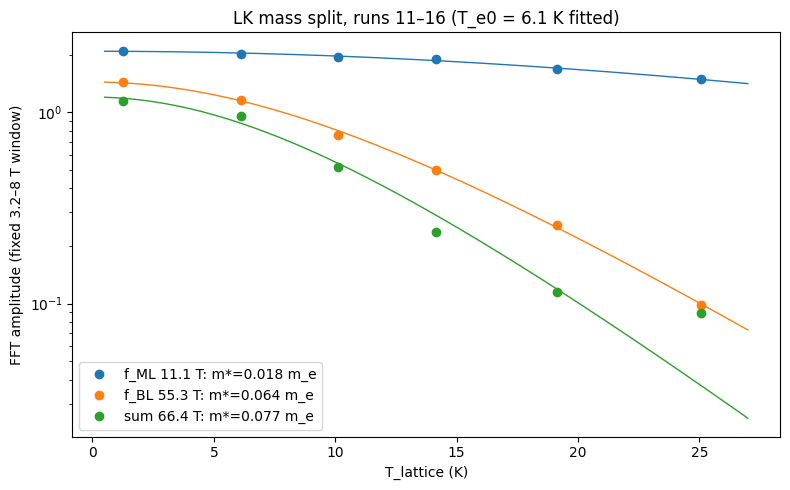

In [11]:
# Runs 11-16: tone amplitudes vs T + joint LK fit (shared T_e0)
from scipy.optimize import differential_evolution, curve_fit

RIDS = [11, 12, 13, 14, 15, 16]
T_l, A11, A55, A66 = [], [], [], []
for rid in RIDS:
    r = run(rid)
    B = r.col_at(1); R = r.col("sr1_X") / 20e-9
    freqs, spec = sdh_fft(R[:, None], B, b_range=(3.2, 8.0), bg_degree=5)
    a = spec[0]
    def amp(F, w):
        m = (freqs > F - w) & (freqs < F + w)
        return a[m].max()
    T_l.append(np.mean(r.col("T_sample")))
    A11.append(amp(11.1, 3)); A55.append(amp(55.3, 4)); A66.append(amp(66.4, 4))
T_l, A11, A55, A66 = map(np.array, (T_l, A11, A55, A66))
B_EFF = 2.0 / (1/3.2 + 1/8.0)

def lk(T, A0, m, Te0):
    x = 14.694 * m * np.sqrt(T**2 + Te0**2) / B_EFF
    return A0 * x / np.sinh(x)

def resid(p):
    Te0, a1, m1, a2, m2 = p
    return (np.sum((np.log(lk(T_l, a1, m1, Te0)) - np.log(A11))**2)
            + np.sum((np.log(lk(T_l, a2, m2, Te0)) - np.log(A55))**2))

sol = differential_evolution(resid, [(0.1, 15), (1, 4), (0.005, 0.06), (1, 4), (0.02, 0.2)], seed=1, tol=1e-10)
Te0, a1, m1, a2, m2 = sol.x
p66, _ = curve_fit(lambda TT, A0, m: lk(TT, A0, m, Te0), T_l, A66, p0=[2.5, m1 + m2], maxfev=20000)
print(f"T_e0 = {Te0:.2f} K | m*(11.1) = {m1:.4f} m_e | m*(55.3) = {m2:.4f} m_e | ratio {m2/m1:.2f}")
print(f"sum tone m* = {p66[1]:.4f} vs m_ML+m_BL = {m1+m2:.4f} | beat exclusion: m(11)<m(55) PASS")

fig, ax = plt.subplots(figsize=(8, 5))
Tf = np.linspace(0.5, 27, 200)
for A, lbl, c, (a0, m) in ((A11, "f_ML 11.1 T", "C0", (a1, m1)),
                            (A55, "f_BL 55.3 T", "C1", (a2, m2)),
                            (A66, "sum 66.4 T", "C2", (p66[0], p66[1]))):
    ax.semilogy(T_l, A, "o", color=c, label=f"{lbl}: m*={m:.3f} m_e")
    ax.semilogy(Tf, lk(Tf, a0, m, Te0), "-", color=c, lw=1)
ax.set_xlabel("T_lattice (K)"); ax.set_ylabel("FFT amplitude (fixed 3.2–8 T window)")
ax.set_title(f"LK mass split, runs 11–16 (T_e0 = {Te0:.1f} K fitted)")
ax.legend()
fig.tight_layout()


**Read (runs 11–16 — the LK mass split, the call's firming step):**

- **Two distinct cyclotron masses**: m*(f_ML = 11.1 T) = **0.018 m_e** (light, Dirac-like) vs m*(f_BL = 55.3 T) = **0.064 m_e** (heavy, bilayer-like) — ratio 3.5, joint-fit residuals ≤ 5% across all six rungs. **Two masses = two genuine bands** (recipe: the deciding cross-check).
- **Beat exclusion: decisive PASS** — the 11.1 T component is *lighter* than the main branch; a beat damps with the sum of parent masses and cannot be lighter than either parent.
- **Breakdown assignment mass-confirmed**: the 66.4 T tone fits m* = 0.077 m_e ≈ m_ML + m_BL = 0.082 (−6%) — a breakdown orbit through both pockets carries the combined mass. The F_L-tone-origin fork is closed quantitatively.
- **Electron-temperature floor**: fitted T_e0 = 6.1 K (shared across branches), consistent with the rig's known ~8 K-scale T_e; the bottom rungs' flatness is fully explained by it.
- **Labeling**: light/heavy at this density is read from the fit, not a prior — but with f_ML/F_L = 17% and m_ML/m_BL = 0.29 both matching the ML-Dirac/BL-parabolic assignment, the labels stand (model m* emission still absent — model TODO; labeling by mass ratio flagged accordingly).
- **Hedges on the fit itself** (flagged for expert review per recipe — no automated LK fit exists in the corpus): B_eff = harmonic-window convention (4.57 T); FFT-window amplitudes rather than single-B amplitudes; mount→device gradient enters T absolutely (rig card) — masses carry ~10%-scale systematic, the *split* and ordering are robust.

**CALL ADDENDUM (supersedes hedge (a) of the step-7 call): QC0426 = ABA (Bernal), strong → now mass-confirmed.** The per-branch LK masses convert "two frequencies" into "two bands with distinct masses"; the exotic-mixing alternative is excluded by the beat test and the breakdown-sum mass. All named firming steps available on this rig are done.
